# Figures

## Load simulation data

In [3]:
include("packages.jl")

filename = "output/sol_2025-11-26_15-24.jld2"

@load filename sol local_tags_list

🔧 Julia started with 8 threads


2-element Vector{Symbol}:
 :sol
 :local_tags_list

## Data preparation

In [4]:
df_list = sequence_dataframes(sol, local_tags_list); # Divide sequences in a list of dataframes that have the metabolites for all and the ribosomes for one sequence
sequences = Dict(x => i for (i, x) in enumerate(local_tags_list[1].seq_names)) # Dictionary that connects the index with the name of a sequence in local_tags_list
println("Sequences in data set:")
for i in eachindex(local_tags_list[1].seq_names)
    println(local_tags_list[1].seq_names[i])
end

Sequences in data set:
lpp
rplE
rplU
rpmJ
tufA
fusA
ompF
tufB
acpP
rpsK
gapA
rpsL
rpsM
hpaBC
ddc


## Translation elongation rate profile

In [6]:
default(
	linewidth 	= 3,
	guidefont 	= font(26),
	tickfont 	= font(18),
	legendfont	= font(18)
	)

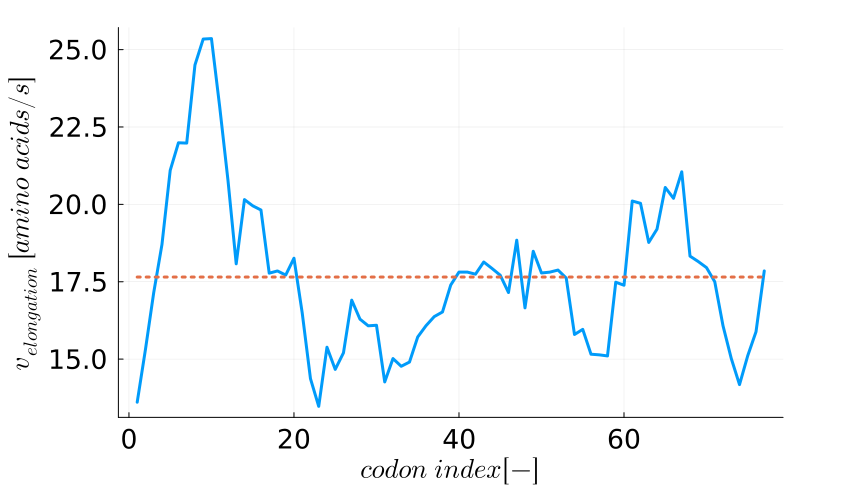

In [15]:
# Function input
sequence_name    = "lpp"
idx         = sequences[sequence_name]
tags        = local_tags_list[idx]
y           = df_list[idx][end,2:end] |> collect;
c_RIB       = y[tags.idx_first_codon:end];

# Calculation
V_TL_EL         = calculate_V_TL_EL(tags, y);
V_EL_smooth, h1 = V_TL_EL_smooth(tags, V_TL_EL, c_RIB)

# Plotting
plot(V_EL_smooth, xlabel = L"codon\ index [-]", 
	ylabel = L"v_{elongation}\ [amino\ acids/s]",
	size = (850, 500), left_margin = 5mm, bottom_margin = 7mm, top_margin = 5mm, right_margin = 15mm,
	legend=:topright, legendfontsize = 18, label = false)
plot!(h1, linestyle =:dot, label = false)

## Time courses of state variables

In [17]:
sequence_name    = "rplE"
idx         = sequences[sequence_name]

variable  = :PRT

t           = df_list[idx].time
metabolite  = df_list[idx][!,variable];

In [18]:
default(
	linewidth 	= 3,
	guidefont 	= font(18),
	tickfont 	= font(18),
	legendfont	= font(8)
	)

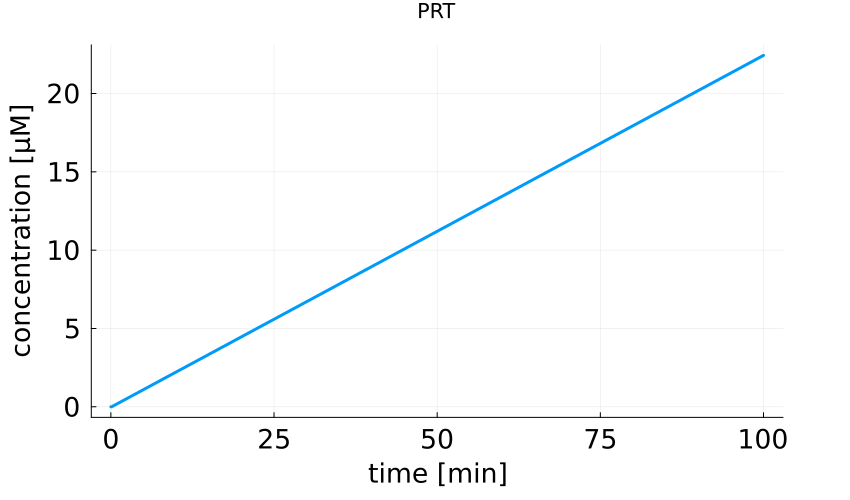

In [19]:
# Plotting
plot(t, metabolite, xlabel = "time [min]", 
	ylabel = "concentration [µM]", title = String(variable),
	size = (850, 500), left_margin = 5mm, bottom_margin = 7mm, top_margin = 5mm, right_margin = 15mm,
	legend=:topright, legendfontsize = 18, label = false)

#### Save figure

In [ ]:
foldername 	= joinpath(pwd(),"output" ,"plots") 
filename 	= String(variable)
filepath = joinpath(foldername, filename)
savefig(filepath)

"c:\\Users\\cedri\\TXTLv2\\src\\output\\plots"

## Translation rate

In [54]:
translation_rate = calculate_translation_rate(df_list[idx])

0.0028968554919308496

## Overview over pool metabolites

In [6]:
example = df_list[end]
pool = example[end, 1:137]
for i in pool
    println(i)
end

100.0
20.110651163109353
16.531760492925024
0.00038936865769000046
0.0026233922385414483
2.766332649649707
1.7925999941779511
0.02009325204165033
0.10968809242799928
0.0007801584852453583
0.006238943303181688
0.09468957518879982
24.22863570370125
15.794032290578889
23.678808975288828
33.12250947128726
1.2234856513006988e-6
0.40814012276290107
0.23834928077948742
2.499412587114805
0.006627992880111904
0.0005452150903493489
0.0005984173047460416
0.0011865683102757648
0.00031026292532207103
0.00303188064943506
3.652826167236108e-5
0.0016567759915682191
0.00022869337241925722
0.0030526959261352156
0.004198555302765561
0.0026650077261159465
0.0002763575792753207
0.0004362430102463737
4.975708958169956e-5
0.0001171237328904962
0.005172243698117158
0.0001727773681762779
0.0016542648379212826
0.000265938000185388
0.0017136705466210343
5.1876119896323124e-5
0.00027170274197807953
0.012038793645618174
7.69554575844505e-5
6.463914693938362e-5
-1.1136502509800918e-71
0.00021455984106838707
1.08752

## Analysis of E.coli gene set

In [5]:
include("packages.jl")

# Load data
mRNA_copy_numbers	= to_DataFrame(readmatrix("../data/input/mRNA_copy_numbers.xlsx", "mRNA_copy_number", "A1:E2472"))
first(mRNA_copy_numbers,3)

🔧 Julia started with 8 threads


Row,Gene,Locus_tag,Length,GeneID,mRNA_molecules_per_cell
,Any,Any,Any,Any,Any
1,lpp,b1677,78,946175,63.6042
2,rplE,b3308,179,947800,57.9722
3,rplU,b3186,103,949057,57.4624


In [6]:
size(mRNA_copy_numbers,1)
# Initialization of arrays 
number_of_genes = zeros(size(mRNA_copy_numbers,1))
number_of_mRNA  = zeros(size(mRNA_copy_numbers,1))
mRNA_molecules  = 0

for (idx, gene) in enumerate(mRNA_copy_numbers.mRNA_molecules_per_cell)
    mRNA_molecules += gene
    number_of_genes[idx] = idx
    number_of_mRNA[idx]  = mRNA_molecules
end


In [15]:
# 1. Schwellenwert berechnen (90% vom Maximum)
threshold = 0.90 * maximum(number_of_mRNA)

# 2. Den ersten Index finden, an dem y diesen Wert erreicht oder überschreitet
idx = findfirst(val -> val >= threshold, number_of_mRNA)

# 3. Den entsprechenden x-Wert abrufen
x_value = number_of_genes[idx]

println("Der Index ist: $idx")
println("Der x-Wert bei 90% ist: $x_value")

Der Index ist: 1269
Der x-Wert bei 90% ist: 1269.0


In [12]:
maximum(number_of_mRNA)*0.9

9242.156150153856

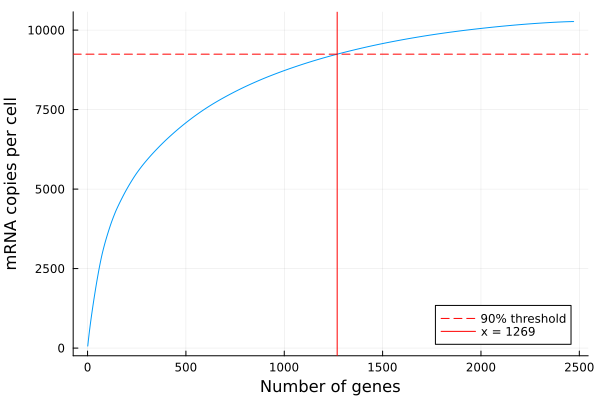

In [34]:
plot(number_of_genes, number_of_mRNA,
xlabel = "Number of genes",
ylabel = "mRNA copies per cell",
label  = false)

# 2. Horizontale Linie bei 90% des Max-Werts einfügen
hline!([threshold], color=:red, linestyle=:dash, label="90% threshold")

# 3. Vertikale Linie beim entsprechenden X-Wert einfügen
vline!([x_value], color=:red, label="x = $(Int(x_value))")

In [24]:
mean_length = mean(skipmissing(mRNA_copy_numbers.Length))
codons = Int(round(mean_length))*Int(x_value)

413694

In [38]:
mean_length

325.6269879518072

In [37]:
number_of_genes[end]*mean_length

804624.2872289156

In [25]:
println("Number of codons necessary for 90% solution: ", codons)

Number of codons necessary for 90% solution: 413694


In [8]:
sum(skipmissing(mRNA_copy_numbers.Length))+130

675806